# Matching & Non-matching periodic BCs

This example showcases simple periodic boundary conditions.

In [1]:
from tatva import Mesh, Operator
from tatva.compound import Compound, field
from tatva.lifter import Lifter, Fixed, Periodic
from tatva import sparse

import jax
import jax.numpy as jnp


import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

jax.config.update("jax_enable_x64", True)

In [2]:
# [collapse: code] Color scheme for plots


# just a custom color scheme for plots
from matplotlib.colors import LinearSegmentedColormap

tatva_colors = {
    "green": "#b9f8cf",  # Low stress
    "yellow": "#ffeba5",  # Mild stress
    "orange": "#ffa683",  # Moderate stress
    "pink": "#ff5d7f",  # High stress
}

color_list = [
    tatva_colors["green"],
    tatva_colors["yellow"],
    tatva_colors["orange"],
    tatva_colors["pink"],
]

tatva_cmap = LinearSegmentedColormap.from_list("tatva_stress", color_list, N=256)

### Simple physics for this example

Basic Neo-hookean elasticity

In [3]:
from jax import Array
from jax_autovmap import autovmap
from typing import NamedTuple
import numpy as np


class Material(NamedTuple):
    """Material properties for the elasticity operator."""

    mu: float  # Diffusion coefficient
    lmbda: float  # Diffusion coefficient

    @classmethod
    def from_youngs_poisson_2d(
        cls, E: float, nu: float, plane_stress: bool = False
    ) -> "Material":
        mu = E / 2 / (1 + nu)
        if plane_stress:
            lmbda = 2 * nu * mu / (1 - nu)
        else:
            lmbda = E * nu / (1 - 2 * nu) / (1 + nu)
        return cls(mu=mu, lmbda=lmbda)


@autovmap(grad_u=2)
def compute_deformation_gradient(grad_u: Array) -> Array:
    return jnp.eye(2) + grad_u


@autovmap(grad_u=2, mat=None)
def strain_energy_density(grad_u: Array, mat: Material) -> Array:
    F = compute_deformation_gradient(grad_u)
    C = F.T @ F
    J = jnp.linalg.det(F)
    return (
        mat.mu / 2 * (jnp.trace(C) - 2)  # 2D case
        - mat.mu * jnp.log(J)
        + (mat.lmbda / 2) * (jnp.log(J)) ** 2
    )


@autovmap(grad_u=2, mat=None)
def get_cauchy_stress(grad_u: Array, mat: Material) -> Array:
    F = compute_deformation_gradient(grad_u)
    C = F.T @ F
    J = jnp.linalg.det(F)

    C_inv = jnp.linalg.inv(C)
    S = mat.mu * (jnp.eye(2) - C_inv) + mat.lmbda * jnp.log(J) * C_inv  # 2nd PK
    P = F @ S  # 1st PK

    sigma = (P @ F.T) / J  # Cauchy
    return sigma


@autovmap(grad_u=2, mat=None)
def get_stress(grad_u: Array, mat: Material) -> Array:
    # 2nd Piola-Kirchhoff stress tensor
    F = compute_deformation_gradient(grad_u)
    C = F.T @ F
    J = jnp.linalg.det(F)
    C_inv = jnp.linalg.inv(C)
    S = mat.mu * (jnp.eye(2) - C_inv) + mat.lmbda * jnp.log(J) * C_inv  # 2nd PK
    return S


def von_mises_stress(sig):
    s_xx, s_yy, s_xy = sig[..., 0, 0], sig[..., 1, 1], sig[..., 0, 1]
    return np.sqrt(s_xx**2 - s_xx * s_yy + s_yy**2 + 3 * s_xy**2)


## Matching boundaries

### 1. Define mesh & Lifter

For matching boundaries, we can use the built-in `Periodic` constraint.

In [4]:
n = 20
mesh = Mesh.unit_square(n, n)


class Solution(Compound, mesh=mesh):
    u = field((-1, 2))


bottom = jnp.where(jnp.isclose(mesh.coords[:, 1], 0))[0]
top = jnp.where(jnp.isclose(mesh.coords[:, 1], 1))[0]
right = jnp.where(mesh.coords[:, 0] == 1)[0]
left = jnp.where(mesh.coords[:, 0] == 0)[0]
corner_0 = jnp.where((mesh.coords[:, 0] == 0) & (mesh.coords[:, 1] == 0))[0]

lifter = Lifter(
    mesh.coords.shape[0] * 2,
    Fixed(Solution.u[corner_0]),
    Periodic(Solution.u[right, :], Solution.u[left, :]),
    Periodic(Solution.u[top, :], Solution.u[bottom, :]),
)

### 2. Functionals & Differentiation

In [5]:
from tatva.element.base import Tri3


def energy_functional(
    z: Array,  # flat array of reduced dofs
    op: Operator,  # fem operator
    lifter: Lifter,  # lifting operator
    mat: Material,
) -> Array:
    z_full = lifter.lift_from_zeros(z)  # lift operation
    (u,) = Solution(z_full)  # reshape flat array into fields
    grad_u = op.grad(u)
    psi = strain_energy_density(grad_u, mat)
    return op.integrate(psi)


op = Operator(mesh, Tri3())
mat = Material.from_youngs_poisson_2d(1e3, 0.3)
sparsity = sparse.pattern_from_energy(
    energy_functional, lifter.size_reduced, op, lifter, mat
)
colored_matrix = sparse.ColoredMatrix.from_csr(sparsity)

load_left = jnp.sin(jnp.pi * 2 * mesh.coords[left, 1]) * 1e2 * (10 / n)

gradient = jax.grad(energy_functional)


def residual(
    z: Array, load: Array, op: Operator, lifter: Lifter, mat: Material
) -> Array:
    return gradient(z, op, lifter, mat) - load


jac = sparse.jacfwd(residual, colored_matrix)

### 3. Solve (using `soldis`)

See https://github.com/smec-ethz/soldis

In [6]:
from soldis import newton, linear

solver = newton.NewtonSolver(
    jax.jit(residual),
    linear.SparseTatva(),
    jax.jit(jac),
    maxiter=20,
    tol=1e-8,
    verbose=True,
)

z_f_0 = jnp.zeros(lifter.size_reduced)
load = lifter.reduce(jnp.zeros(lifter.size).at[Solution.u[left, 0]].set(load_left))
sol = solver.root(z_f_0, load, op, lifter, mat)

Iteration 0/20; Residual 158.11388300841898
Iteration 1/20; Residual 50.31942815444444
Iteration 2/20; Residual 5.392982160758012
Iteration 3/20; Residual 0.055561218024660665
Iteration 4/20; Residual 8.541463917842835e-06
Iteration 5/20; Residual 4.409854234892971e-13


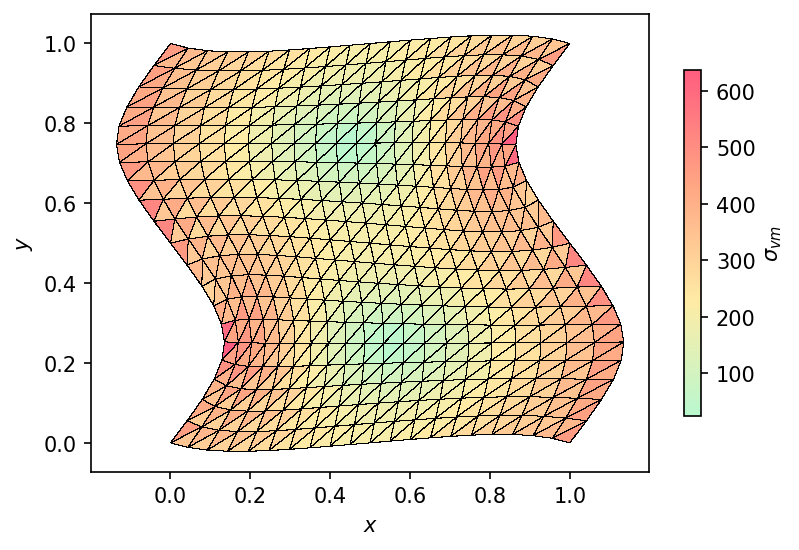

In [7]:
(u_sol,) = Solution(lifter.lift_from_zeros(sol.value))

x_sol = u_sol + mesh.coords
tri = Triangulation(x_sol[:, 0], x_sol[:, 1], mesh.elements)

fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
ax.set_aspect("equal")

sig = get_cauchy_stress(op.grad(u_sol), mat)
vm = von_mises_stress(sig)
cb = ax.tripcolor(
    tri, vm.flatten(), color="k", cmap=tatva_cmap, lw=0.01, rasterized=True
)
ax.set(xlabel="$x$", ylabel="$y$")
plt.colorbar(cb, shrink=0.5, label="$\\sigma_{vm}$")
plt.show()

## Non-matching boundaries

For non-matching boundaries, a simple node-to-node coupling is not possible. In this case, we constrain the dofs on the right edge to be the interpolated value at $x - 1$.

To do this in `tatva` you create a small custom constraint.

In [8]:
# [collapse: code] Mesh Generation

import gmsh


def get_mesh(n_1: int = 10, n_2: int = 20):
    gmsh.model.add("tatva_non_matching_square")

    # 1. Define Geometry Points (Unit Square)
    lc = 1.0  # Base characteristic length (will be overridden by transfinite specs)
    p1 = gmsh.model.geo.addPoint(0.0, 0.0, 0.0, lc)
    p2 = gmsh.model.geo.addPoint(1.0, 0.0, 0.0, lc)
    p3 = gmsh.model.geo.addPoint(1.0, 1.0, 0.0, lc)
    p4 = gmsh.model.geo.addPoint(0.0, 1.0, 0.0, lc)

    # 2. Define Curves
    # c_bottom: y=0, c_right: x=1, c_top: y=1, c_left: x=0
    c_bottom = gmsh.model.geo.addLine(p1, p2)
    c_right = gmsh.model.geo.addLine(p2, p3)
    c_top = gmsh.model.geo.addLine(p3, p4)
    c_left = gmsh.model.geo.addLine(p4, p1)

    # 3. Create Surface
    curve_loop = gmsh.model.geo.addCurveLoop([c_bottom, c_right, c_top, c_left])
    surface = gmsh.model.geo.addSurfaceLoop([curve_loop])
    # Creating a plane surface automatically sets it up for triangular meshing
    surf = gmsh.model.geo.addPlaneSurface([curve_loop])

    gmsh.model.geo.synchronize()

    # 4. Enforce Non-Matching Node Counts on Boundaries
    # mesh.setTransfiniteCurve requires total number of nodes (including endpoints)
    # x=0 (c_left)   -> 20 nodes
    # x=1 (c_right)  -> 10 nodes
    # y=0 (c_bottom) -> 20 nodes
    # y=1 (c_top)    -> 10 nodes
    gmsh.model.mesh.setTransfiniteCurve(c_left, n_1)
    gmsh.model.mesh.setTransfiniteCurve(c_right, n_2)
    gmsh.model.mesh.setTransfiniteCurve(c_bottom, n_1)
    gmsh.model.mesh.setTransfiniteCurve(c_top, n_2)

    # Note: We do NOT call setTransfiniteSurface. Leaving the surface unstructured
    # allows Gmsh to bridge the 20-to-10 node discrepancy gracefully with triangles.

    # 5. Generate Mesh
    gmsh.model.mesh.generate(2)


n = 10
gmsh.initialize()
get_mesh(n, 3 * n)
mesh = Mesh(jnp.asarray(mesh.coords), jnp.asarray(mesh.elements))
gmsh.finalize()

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000210797s, CPU 0s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.011578s, CPU 0.017973s)
Info    : 412 nodes 826 elements


### 1. Define Constraint & Lifter

In [9]:
from tatva.lifter import Constraint
from tatva.element import Tri3

left = jnp.where(jnp.isclose(mesh.coords[:, 0], 0))[0]
right = jnp.where(jnp.isclose(mesh.coords[:, 0], 1))[0]
bottom = jnp.where(jnp.isclose(mesh.coords[:, 1], 0))[0]
top = jnp.where(jnp.isclose(mesh.coords[:, 1], 1))[0]
corner = jnp.where((mesh.coords[:, 0] == 0) & (mesh.coords[:, 1] == 0))[0]


class Solution(Compound, mesh=mesh):
    u = field((-1, 2))


class PeriodicNonMatching(Constraint):
    def __init__(
        self, dofs: Array, map_coords: Array, compound: type[Solution], op: Operator
    ):
        self.dofs = dofs
        self.map_coords = map_coords
        self.compound = compound
        self.interpolate = jax.jit(op.make_interpolate(map_coords))

    def apply_lift(self, u_full: Array) -> Array:
        # Get the solution fields from the full dofs
        (u,) = self.compound(u_full)

        # Interpolate the solution at the mapped coordinates
        u_mapped = self.interpolate(u)

        # Return the lifted solution
        return u_full.at[self.dofs].set(u_mapped.flatten())


op = Operator(mesh, Tri3())

right_to_left = PeriodicNonMatching(
    dofs=Solution.u[right, :],
    map_coords=mesh.coords[right, :]
    - jnp.array([1.0, 0.0]),  # Map right edge to left edge
    compound=Solution,
    op=op,
)

top_to_bottom = PeriodicNonMatching(
    dofs=Solution.u[top, :],
    map_coords=mesh.coords[top, :]
    - jnp.array([0.0, 1.0]),  # Map top edge to bottom edge
    compound=Solution,
    op=op,
)

lifter = Lifter(
    Solution.size,
    Fixed(Solution.u[corner]),
    right_to_left,
    top_to_bottom,
)

### 2. Functionals & Differentiation

In [10]:
def energy_functional(
    z: Array,  # flat array of reduced dofs
    op: Operator,  # fem operator
    lifter: Lifter,  # lifting operator
    mat: Material,
) -> Array:
    z_full = lifter.lift_from_zeros(z)  # lift operation
    (u,) = Solution(z_full)  # reshape flat array into fields
    grad_u = op.grad(u)
    psi = strain_energy_density(grad_u, mat)
    return op.integrate(psi)


mat = Material.from_youngs_poisson_2d(1e3, 0.3)
sparsity = sparse.pattern_from_energy(
    energy_functional, lifter.size_reduced, op, lifter, mat
)
colored_matrix = sparse.ColoredMatrix.from_csr(sparsity)

load_left = jnp.sin(jnp.pi * 2 * mesh.coords[left, 1]) * 0.8e2 * (10 / n)

gradient = jax.grad(energy_functional)


def residual(
    z: Array, load: Array, op: Operator, lifter: Lifter, mat: Material
) -> Array:
    return gradient(z, op, lifter, mat) - load


jac = sparse.jacfwd(residual, colored_matrix)

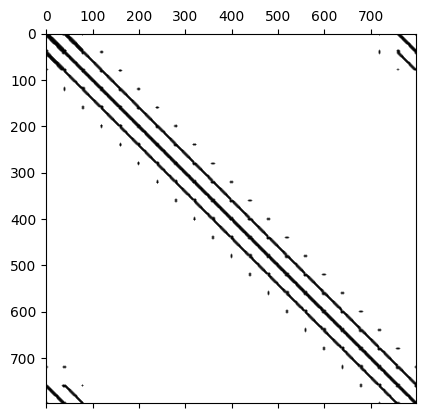

In [11]:
plt.spy(sparsity, markersize=0.1, color="black")

### 3. Solve (using `soldis`)

In [12]:
from soldis import newton, linear

solver = newton.NewtonSolver(
    jax.jit(residual),
    linear.SparseTatva(),
    jax.jit(jac),
    maxiter=20,
    tol=1e-8,
    verbose=True,
)

z_f_0 = jnp.zeros(lifter.size_reduced)
load = lifter.reduce(jnp.zeros(lifter.size).at[Solution.u[left, 0]].set(load_left))
root = jax.jit(solver.root)

In [13]:
# [output: hide]

us = []
for i in jnp.linspace(0, 1, 40):
    print(f"Solving for load factor: {i:.2f}")
    sol = root(z_f_0, load * i, op, lifter, mat)
    us.append(sol.value)

Solving for load factor: 0.00
Iteration 0/20; Residual 0.0
Solving for load factor: 0.03
Iteration 0/20; Residual 6.486723405473599
Iteration 1/20; Residual 0.08313049503362148
Iteration 2/20; Residual 1.2783084279232152e-05
Iteration 3/20; Residual 3.1685261395724405e-13
Solving for load factor: 0.05
Iteration 0/20; Residual 12.973446810947198
Iteration 1/20; Residual 0.3325223577351818
Iteration 2/20; Residual 0.0002046837778995256
Iteration 3/20; Residual 5.643872864656622e-11
Solving for load factor: 0.08
Iteration 0/20; Residual 19.460170216420796
Iteration 1/20; Residual 0.7481778786874689
Iteration 2/20; Residual 0.0010375223366846076
Iteration 3/20; Residual 1.4632000525673716e-09
Solving for load factor: 0.10
Iteration 0/20; Residual 25.946893621894397
Iteration 1/20; Residual 1.3301047825417083
Iteration 2/20; Residual 0.0032849326017010184
Iteration 3/20; Residual 1.4848571243991619e-08
Iteration 4/20; Residual 2.2158096392976213e-13
Solving for load factor: 0.13
Iteration 0

## Visualization

In [14]:
vm_max = 0
for u in us:
    (u_sol,) = Solution(lifter.lift_from_zeros(u))
    sig = get_cauchy_stress(op.grad(u_sol), mat)
    vm = von_mises_stress(sig)
    vm_max = max(vm_max, vm.max())

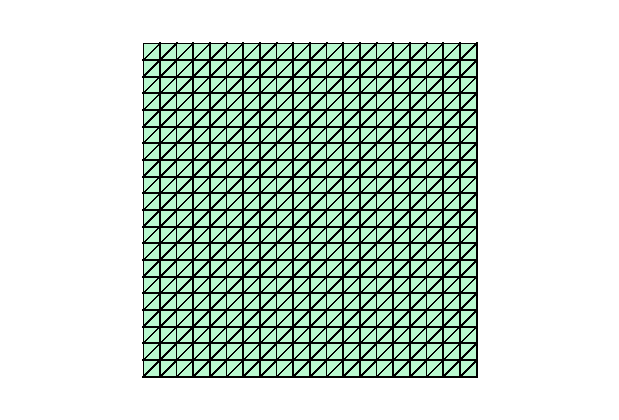

In [ ]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_aspect("equal")
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)
plt.tight_layout(pad=0)


def frame(i):
    ax.clear()
    ax.set(xlim=(-0.4, 1.4), ylim=(-0.1, 1.1))
    (u_sol,) = Solution(lifter.lift_from_zeros(us[i]))

    x_sol = u_sol + mesh.coords
    tri = Triangulation(x_sol[:, 0], x_sol[:, 1], mesh.elements)

    sig = get_cauchy_stress(op.grad(u_sol), mat)
    vm = von_mises_stress(sig)
    cb = ax.tripcolor(
        tri,
        vm.flatten(),
        color="k",
        cmap=tatva_cmap,
        lw=0.01,
        rasterized=True,
        vmax=vm_max,
    )


ax.set(xlabel="$x$", ylabel="$y$")
animation = FuncAnimation(fig, frame, frames=len(us), interval=500, repeat=True)

webm_writer = FFMpegWriter(
    fps=10,
    codec="libvpx-vp9",
    extra_args=["-pix_fmt", "yuva420p"],  # The 'a' stands for Alpha!
)

# 2. Pass the custom writer to the save function
animation.save(
    "periodic.webm",
    writer=webm_writer,
    dpi=300,
    savefig_kwargs={"transparent": True, "facecolor": "none"},
)
